In [41]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Set seaborn style for better looking charts
sns.set_theme(style="darkgrid")
# Standardize colors so Player 0 is always Blue, Player 1 is Orange, etc.
player_palette = {"Player 0": "blue", "Player 1": "orange", "Player 2": "green", "Player 3": "red"}

def load_replay(filepath):
    print(f"Loading {filepath}...")
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            html_content = f.read()
        
        raw_tail = html_content.split('window.kaggle = ', 1)[1]
        json_string_candidate = raw_tail.split('window.kaggle.renderer', 1)[0]
        clean_json_string = json_string_candidate.strip().rstrip(';')
        
        data = json.loads(clean_json_string)
        return data['environment']['steps']
        
    except Exception as e:
        print(f"Failed to parse JSON from HTML: {e}")
        return None

# Load the 4-Player Replay
steps = load_replay("/home/saksham/Documents/kaggle/OrbitWars/replays/replay_match_10_4-player_seed646656.html")

if steps is not None:
    print(f"Successfully loaded {len(steps)} turns.")



Loading /home/saksham/Documents/kaggle/OrbitWars/replays/replay_match_10_4-player_seed646656.html...
Successfully loaded 183 turns.


In [42]:
# --- DATA EXTRACTION ---
attrition_data = []
deployment_data = []
fleet_launches = []

# Track cumulative production over time for all 4 players
cum_prod = {0: 0, 1: 0, 2: 0, 3: 0}
seen_fleets = set()

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    
    garrison = {0: 0, 1: 0, 2: 0, 3: 0}
    transit = {0: 0, 1: 0, 2: 0, 3: 0}
    
    # Tally Planet Economy (Garrison & Production)
    for p in planets:
        owner = p[1]
        ships = p[5]
        prod = p[6]
        
        if owner in cum_prod:
            cum_prod[owner] += prod
            garrison[owner] += ships
            
    # Tally Fleet Economy (Transit & New Launches)
    for f in fleets:
        f_id = f[0]
        owner = f[1]
        ships = f[6]
        
        if owner in transit:
            transit[owner] += ships
            
        # Detect new fleet launches
        if f_id not in seen_fleets and owner in [0, 1, 2, 3]:
            seen_fleets.add(f_id)
            fleet_launches.append({
                'Turn': turn_idx,
                'Player': f'Player {owner}',
                'Ships': ships
            })
            
    # Calculate Data per Player for this Turn
    for player_id in range(4):
        alive_ships = garrison[player_id] + transit[player_id]
        
        attrition_data.append({
            'Turn': turn_idx,
            'Player': f'Player {player_id}',
            'Combat_Losses': max(0, cum_prod[player_id] - alive_ships)
        })
        
        deployment_data.append({
            'Turn': turn_idx,
            'Player': f'Player {player_id}',
            'Garrison': garrison[player_id],
            'Transit': transit[player_id],
            'Total': alive_ships
        })



In [43]:
MY_PLAYER = 2

OPPONENTS = [p for p in range(4) if p != MY_PLAYER]
print(f"Tracking Player {MY_PLAYER} as 'Mine'.")
print(f"Tracking Players {OPPONENTS} as 'Opponents'.")

# Convert Block 2 lists to DataFrames
df_dep = pd.DataFrame(deployment_data)
df_attrition = pd.DataFrame(attrition_data)
df_launches = pd.DataFrame(fleet_launches)

Tracking Player 2 as 'Mine'.
Tracking Players [0, 1, 3] as 'Opponents'.


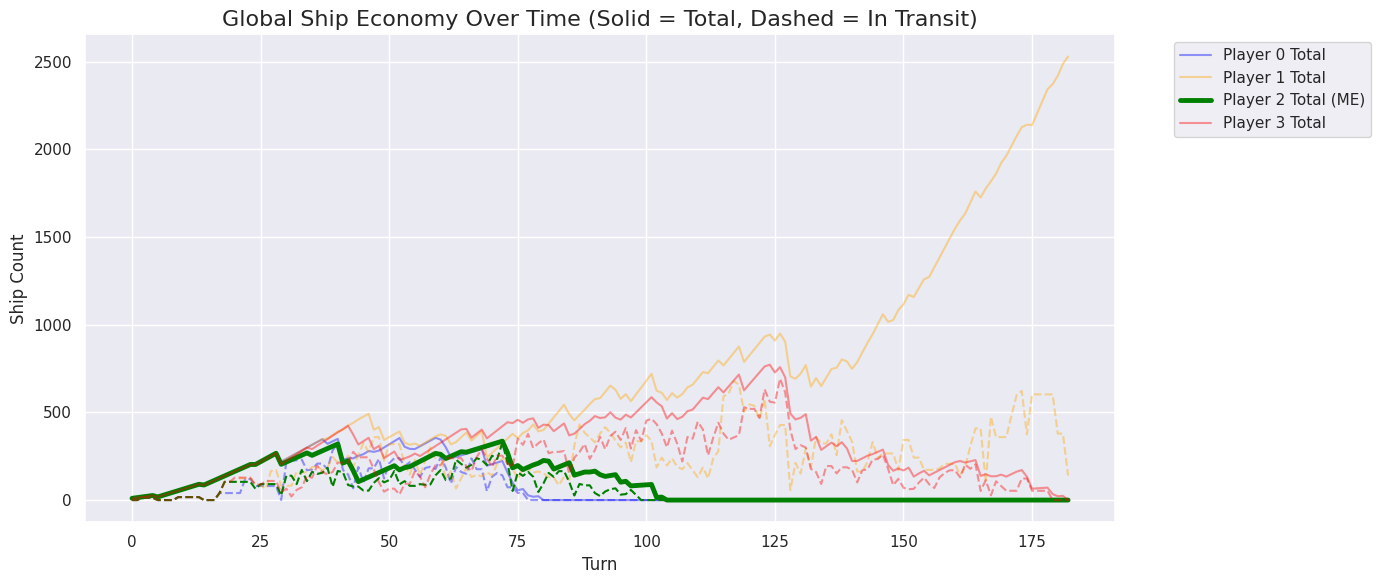

In [44]:
# Block 4: Global Ship Economy (4-Player)
plt.figure(figsize=(14, 6))

for p in range(4):
    p_name = f'Player {p}'
    p_data = df_dep[df_dep['Player'] == p_name]
    
    # Highlight your player
    lw = 3.5 if p == MY_PLAYER else 1.5
    alpha = 1.0 if p == MY_PLAYER else 0.4
    label_suffix = " (ME)" if p == MY_PLAYER else ""
    
    plt.plot(p_data['Turn'], p_data['Total'], 
             label=f'{p_name} Total{label_suffix}', 
             color=player_palette[p_name], linewidth=lw, alpha=alpha)
    
    plt.plot(p_data['Turn'], p_data['Transit'], 
             linestyle='--', color=player_palette[p_name], alpha=alpha)

plt.title('Global Ship Economy Over Time (Solid = Total, Dashed = In Transit)', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Ship Count', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

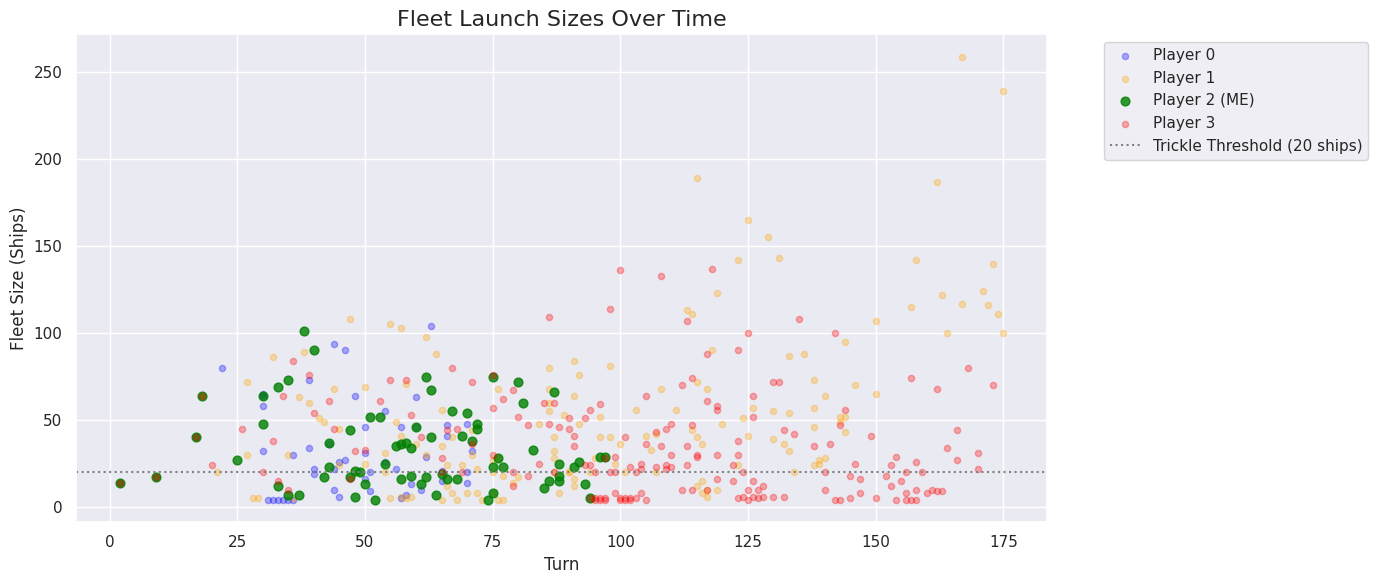

In [45]:
# Block 5: Fleet Launch Sizes Over Time
plt.figure(figsize=(14, 6))

for p in range(4):
    p_name = f'Player {p}'
    p_launches = df_launches[df_launches['Player'] == p_name]
    
    alpha = 0.8 if p == MY_PLAYER else 0.3
    size = 40 if p == MY_PLAYER else 20
    label_suffix = " (ME)" if p == MY_PLAYER else ""
    
    plt.scatter(p_launches['Turn'], p_launches['Ships'], 
                color=player_palette[p_name], alpha=alpha, s=size, 
                label=f'{p_name}{label_suffix}')

plt.axhline(y=20, color='gray', linestyle=':', label='Trickle Threshold (20 ships)')
plt.title('Fleet Launch Sizes Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Fleet Size (Ships)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

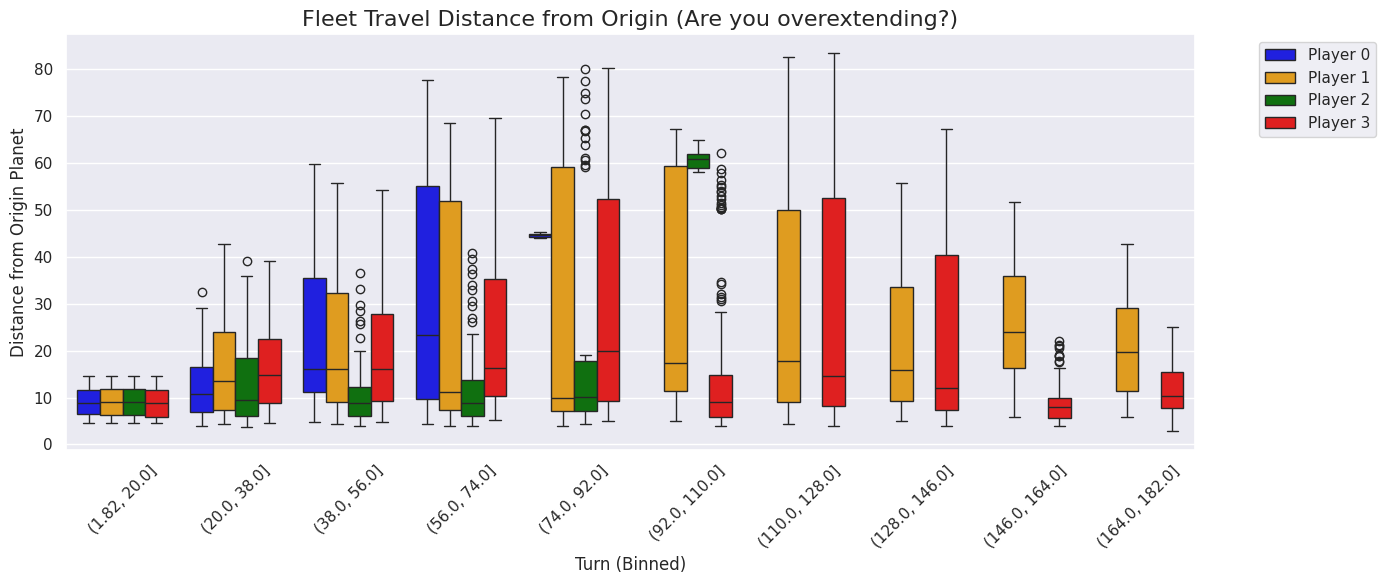

In [46]:
# Block 6: Fleet Travel Distance Approximation
travel_data = []
initial_planets = steps[0][0]['observation']['planets']
planet_coords = {p[0]: (p[2], p[3]) for p in initial_planets}

for turn_idx, step in enumerate(steps):
    fleets = step[0]['observation'].get('fleets', [])
    for f in fleets:
        owner = f[1]
        fx, fy = f[2], f[3]
        origin_id = f[5]
        
        ox, oy = planet_coords.get(origin_id, (50, 50))
        dist_from_home = math.hypot(fx - ox, fy - oy)
        
        if owner in [0, 1, 2, 3]:
            travel_data.append({
                'Turn': turn_idx,
                'Player': f'Player {owner}',
                'Distance': dist_from_home
            })

df_travel = pd.DataFrame(travel_data)

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_travel, 
    x=pd.cut(df_travel['Turn'], bins=10), 
    y='Distance', 
    hue='Player',
    palette=player_palette
)
plt.title('Fleet Travel Distance from Origin (Are you overextending?)', fontsize=16)
plt.xlabel('Turn (Binned)', fontsize=12)
plt.ylabel('Distance from Origin Planet', fontsize=12)
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

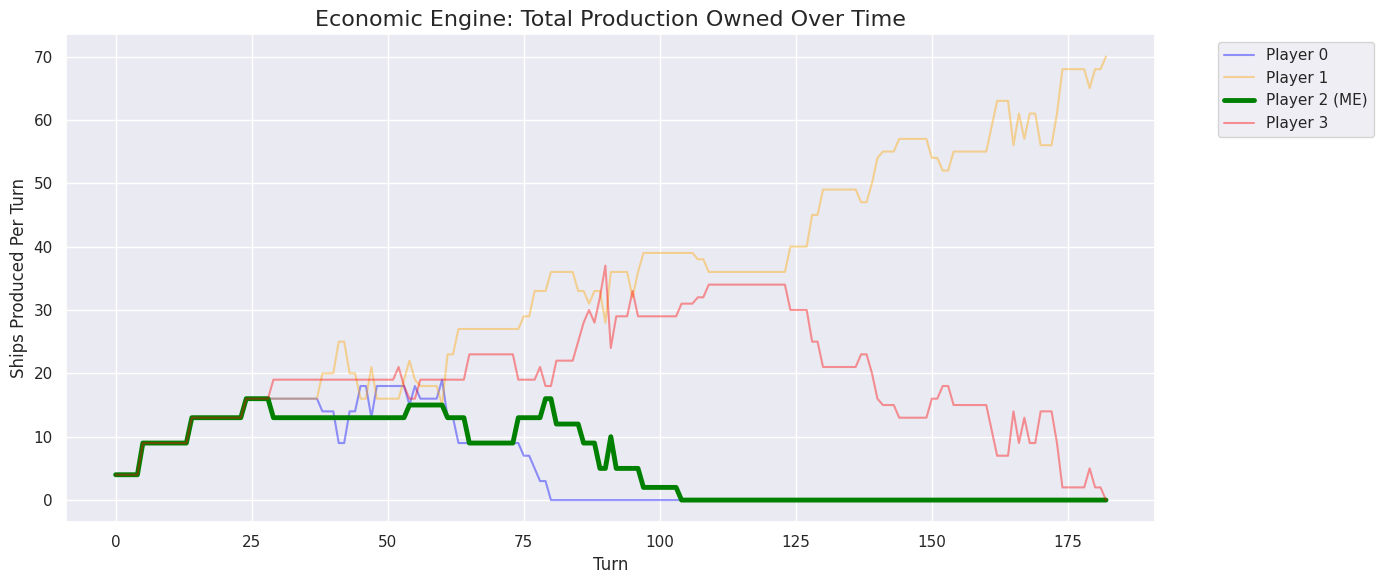

In [47]:
# Block 7: Planet Production Ownership Over Time
production_data = []

for turn_idx, step in enumerate(steps):
    planets = step[0]['observation']['planets']
    prod = {0: 0, 1: 0, 2: 0, 3: 0}
    
    for p in planets:
        owner = p[1]
        if owner in prod:
            prod[owner] += p[6]
            
    row = {'Turn': turn_idx}
    for p_id in range(4):
        row[f'Player {p_id}'] = prod[p_id]
    production_data.append(row)

df_prod = pd.DataFrame(production_data)

plt.figure(figsize=(14, 6))
for p in range(4):
    p_name = f'Player {p}'
    lw = 3.5 if p == MY_PLAYER else 1.5
    alpha = 1.0 if p == MY_PLAYER else 0.4
    label_suffix = " (ME)" if p == MY_PLAYER else ""
    
    plt.plot(df_prod['Turn'], df_prod[p_name], 
             label=f'{p_name}{label_suffix}', 
             color=player_palette[p_name], linewidth=lw, alpha=alpha)

plt.title('Economic Engine: Total Production Owned Over Time', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Ships Produced Per Turn', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

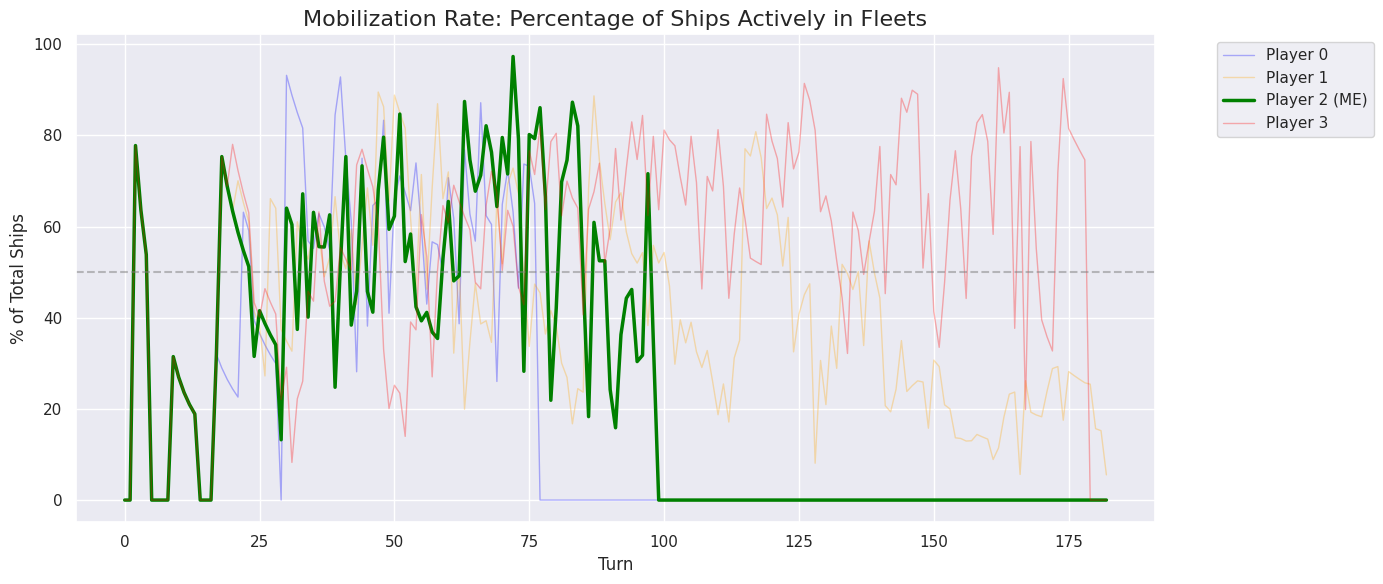

In [48]:
# Block 8: Resource Utilization (% of Ships in Transit)
df_dep['Active_Pct'] = (df_dep['Transit'] / df_dep['Total']) * 100
df_dep['Active_Pct'] = df_dep['Active_Pct'].fillna(0)

plt.figure(figsize=(14, 6))

for p in range(4):
    p_name = f'Player {p}'
    p_data = df_dep[df_dep['Player'] == p_name]
    
    lw = 2.5 if p == MY_PLAYER else 1.0
    alpha = 1.0 if p == MY_PLAYER else 0.3
    label_suffix = " (ME)" if p == MY_PLAYER else ""
    
    plt.plot(p_data['Turn'], p_data['Active_Pct'], 
             label=f'{p_name}{label_suffix}', 
             color=player_palette[p_name], linewidth=lw, alpha=alpha)

plt.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
plt.title('Mobilization Rate: Percentage of Ships Actively in Fleets', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('% of Total Ships', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

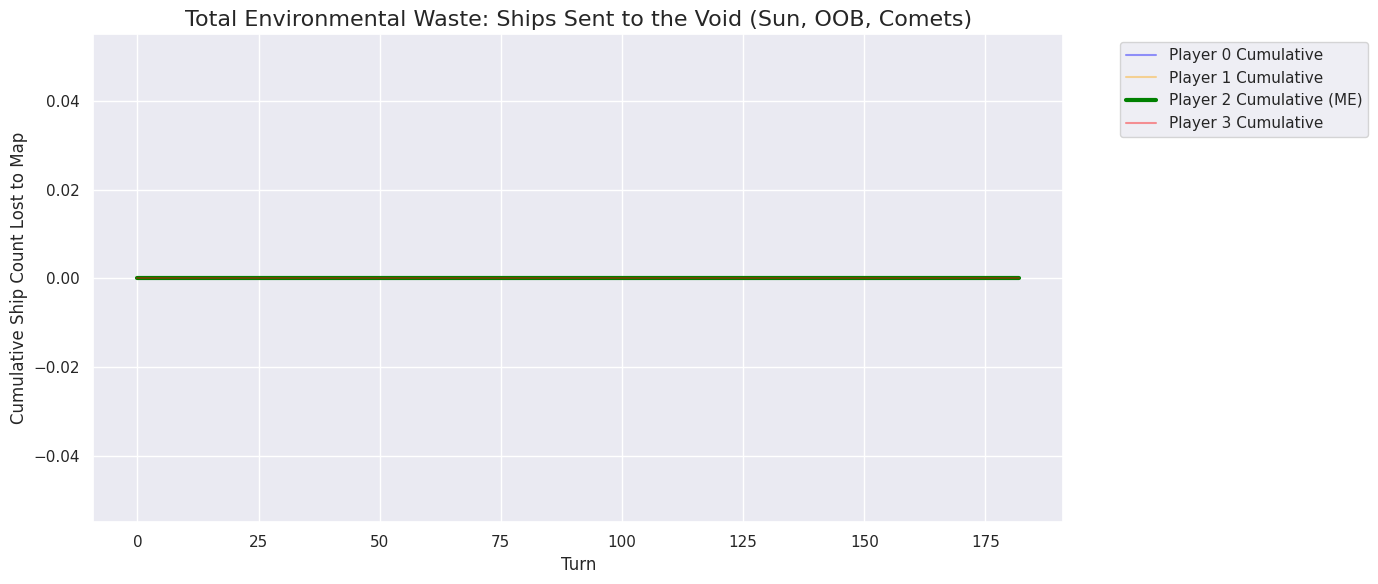

In [49]:
# Block 9: Comprehensive Void Loss Tracker
void_loss_data = []
prev_comet_ships = {} 
tracked_fleets = {}

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    comet_ids = set(obs.get('comet_planet_ids', []))
    
    void_counts = {0: 0, 1: 0, 2: 0, 3: 0}
    
    # 1. Comet Expirations
    current_comets = {p[0]: (p[1], p[5]) for p in planets if p[0] in comet_ids}
    for c_id, (owner, ships) in prev_comet_ships.items():
        if c_id not in current_comets and owner in void_counts:
            void_counts[owner] += ships
    prev_comet_ships = current_comets

    # 2. Fleet Physics Deletions
    current_fleets = {f[0]: (f[1], f[6], f[2], f[3], f[4]) for f in fleets}
    for f_id, (owner, ships, x, y, angle) in tracked_fleets.items():
        if f_id not in current_fleets and owner in void_counts:
            log_ratio = max(0.0, math.log(max(1, ships)) / math.log(1000))
            speed = 1.0 + 5.0 * (log_ratio ** 1.5)
            next_x, next_y = x + speed * math.cos(angle), y + speed * math.sin(angle)
            
            oob = next_x < 0 or next_x > 100 or next_y < 0 or next_y > 100
            hit_sun = math.hypot(next_x - 50, next_y - 50) <= 10.0
            
            if oob or hit_sun:
                void_counts[owner] += ships
                
    tracked_fleets = current_fleets
    
    row = {'Turn': turn_idx}
    for p in range(4):
        row[f'Player {p}'] = void_counts[p]
    void_loss_data.append(row)

df_void = pd.DataFrame(void_loss_data)

plt.figure(figsize=(14, 6))
for p in range(4):
    p_name = f'Player {p}'
    df_void[f'{p_name}_Cum'] = df_void[p_name].cumsum()
    
    lw = 3.0 if p == MY_PLAYER else 1.5
    alpha = 1.0 if p == MY_PLAYER else 0.4
    label_suffix = " (ME)" if p == MY_PLAYER else ""
    
    plt.plot(df_void['Turn'], df_void[f'{p_name}_Cum'], 
             label=f'{p_name} Cumulative{label_suffix}', 
             color=player_palette[p_name], linewidth=lw, alpha=alpha)

plt.title('Total Environmental Waste: Ships Sent to the Void (Sun, OOB, Comets)', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Cumulative Ship Count Lost to Map', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

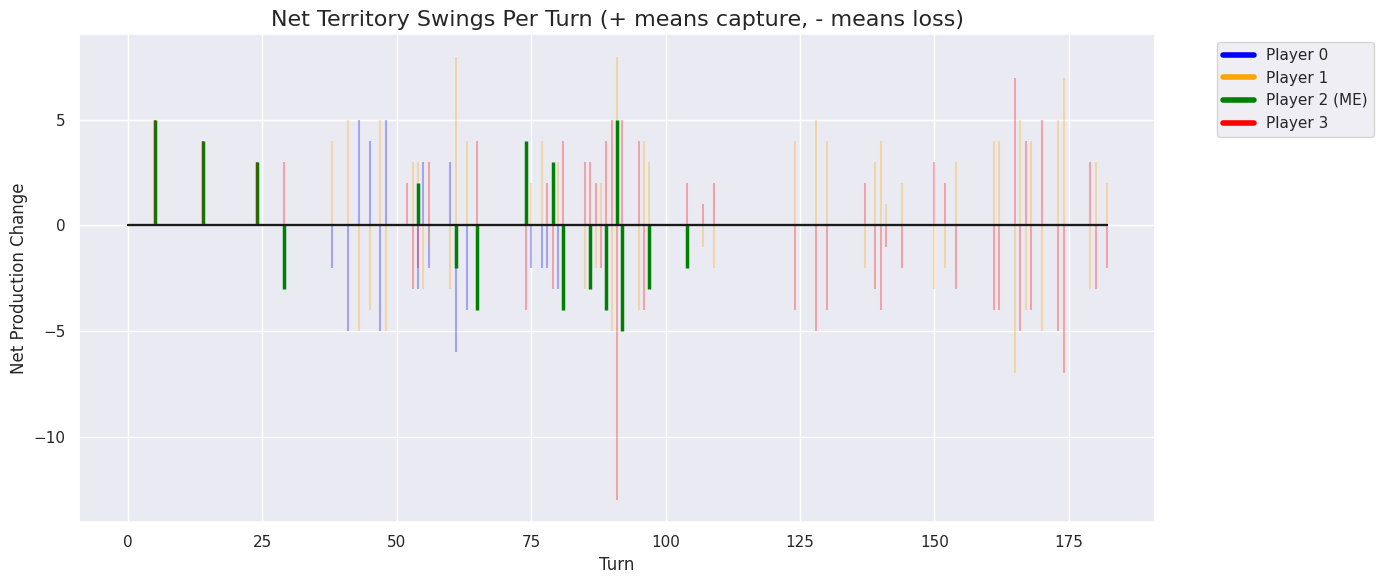

In [50]:
# Block 10: Net Territory Shifts (Production Captured minus Lost)
territory_data = []
prev_planets = {}

for turn_idx, step in enumerate(steps):
    current_planets = {p[0]: p for p in step[0]['observation']['planets']}
    net_shift = {0: 0, 1: 0, 2: 0, 3: 0}
    
    if turn_idx > 0:
        for pid, p in current_planets.items():
            if pid in prev_planets:
                prev_owner, prev_ships, prev_prod = prev_planets[pid]
                curr_owner, curr_ships, curr_prod = p[1], p[5], p[6]
                
                if prev_owner != curr_owner:
                    if curr_owner in net_shift: net_shift[curr_owner] += curr_prod
                    if prev_owner in net_shift: net_shift[prev_owner] -= prev_prod

    row = {'Turn': turn_idx}
    for p in range(4): row[f'Player {p}'] = net_shift[p]
    territory_data.append(row)
    
    prev_planets = {pid: (p[1], p[5], p[6]) for pid, p in current_planets.items()}

df_territory = pd.DataFrame(territory_data)

plt.figure(figsize=(14, 6))
for p in range(4):
    p_name = f'Player {p}'
    alpha = 1.0 if p == MY_PLAYER else 0.3
    
    # We plot this as a stem/bar hybrid for readability
    markerline, stemlines, baseline = plt.stem(
        df_territory['Turn'], df_territory[p_name], 
        linefmt=player_palette[p_name], markerfmt=' ', basefmt="k-", label=p_name
    )
    plt.setp(stemlines, 'alpha', alpha)
    if p == MY_PLAYER: plt.setp(stemlines, 'linewidth', 2.5)

plt.title('Net Territory Swings Per Turn (+ means capture, - means loss)', fontsize=16)
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Net Production Change', fontsize=12)
# Custom legend to avoid duplicate stem entries
handles = [plt.Line2D([0], [0], color=player_palette[f'Player {i}'], lw=4) for i in range(4)]
plt.legend(handles, [f'Player {i}' + (" (ME)" if i == MY_PLAYER else "") for i in range(4)], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()